# 로지스틱회귀 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week02/logistic_regression/lab/logistic_regression.ipynb)

$\hat y = \sigma(w_0 + w_1 x)$ = 1일 확률. 슬라이드의 숫자를 재현하고, 실제 타이타닉 승객 데이터로 해석과 임계값을 다룬다.

- **파트 1**: 선형회귀 경사하강법에서 한 줄 바꿔 로지스틱회귀 → 7시간 92% 재현
- **파트 2**: 타이타닉: 성별 · 객실 등급 · 나이로 생존 예측, 오즈 배수 읽기
- **파트 3**: 임계값을 바꿔 정밀도 · 재현율 보기, PR 곡선과 PR-AUC

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression

## 슬라이드의 예시 데이터

학생 40명의 공부 시간과 합격 여부 (1 = 합격, 0 = 불합격).

In [ ]:
# Same example as the slides: 40 students
x = np.array([1.7, 5.2, 6.2, 0.8, 1.9, 9.3, 1.2, 1.7, 9.5, 6.4,
              4.0, 5.4, 6.8, 3.1, 1.8, 8.0, 6.9, 5.4, 8.3, 5.7,
              9.8, 2.4, 5.8, 5.1, 3.9, 6.1, 2.7, 8.1, 8.7, 1.7,
              4.9, 3.1, 1.3, 9.0, 4.6, 1.9, 6.9, 2.4, 9.1, 2.6])      # study hours
y = np.array([0, 1, 1, 0, 0, 1, 0, 1, 1, 0,
              0, 0, 1, 1, 0, 1, 1, 1, 1, 1,
              1, 0, 1, 1, 0, 1, 0, 1, 1, 0,
              0, 0, 0, 1, 1, 0, 1, 0, 1, 0])      # 1 = passed, 0 = failed
print("passed", y.sum(), "/", len(y))
plt.scatter(x, y, c=y, cmap="coolwarm_r"); plt.xlabel("study hours"); plt.ylabel("passed (1) / failed (0)"); plt.show()

**예상 결과**

```
passed 22 / 40
```

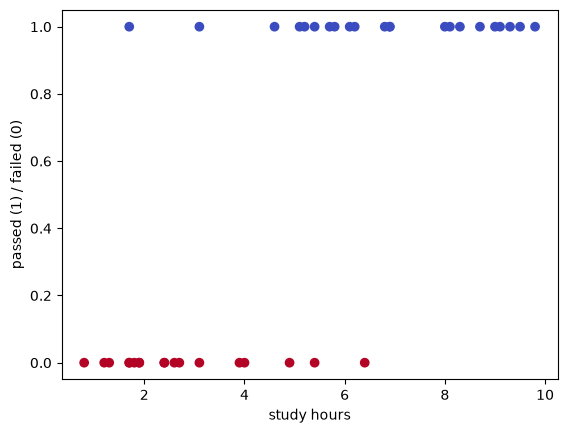

## 파트 1. 시그모이드를 만들고, 선형회귀 코드에서 한 줄만 바꾸기

선형회귀의 기울기: $\frac{1}{m}\sum(\hat y - y)\,x$ (단 $\hat y = w_0 + w_1 x$).
로지스틱회귀도 **같은 식**이고 $\hat y = \sigma(w_0 + w_1 x)$ 만 다르다.

In [ ]:
def sigmoid(z):
    return None             # TODO: σ(z) = 1 / (1 + e^{-z})

for z in [-4, -1, 0, 1, 4]:
    print(f"sigmoid({z:2d}) = {sigmoid(z):.3f}")
zs = np.linspace(-8, 8, 200)
plt.plot(zs, sigmoid(zs)); plt.axhline(0.5, ls="--", color="gray"); plt.xlabel("z"); plt.ylabel("sigmoid(z)"); plt.show()

**예상 결과**

```
sigmoid(-4) = 0.018
sigmoid(-1) = 0.269
sigmoid( 0) = 0.500
sigmoid( 1) = 0.731
sigmoid( 4) = 0.982
```

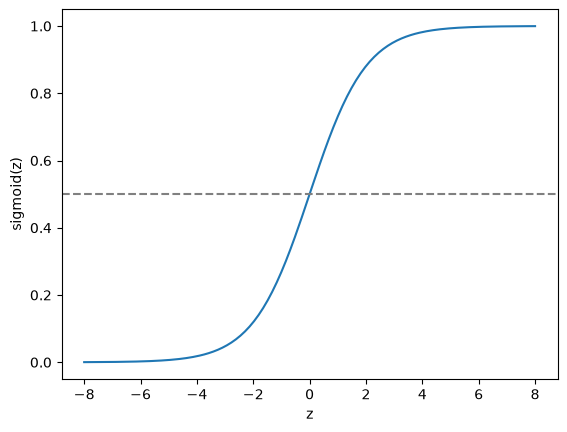

**확인**: $z = 0$ 이면 정확히 0.5, $z$ 가 크면 1, 작으면 0 에 가까워진다. 어떤 실수든 0~1 사이 확률로 바꾼다.

이제 이 함수로 경사하강법을 돌린다.

In [ ]:
def gradient_descent(x, y, alpha=0.1, steps=20000):
    w0, w1 = 0.0, 0.0
    for _ in range(steps):
        y_hat = None            # TODO: the only line that differs from linear regression
        err = y_hat - y
        w0, w1 = w0 - alpha * err.mean(), w1 - alpha * (err * x).mean()
    return w0, w1

w0, w1 = gradient_descent(x, y)
print(f"w0 = {w0:.2f}, w1 = {w1:.2f}")
print(f"decision boundary x = {-w0 / w1:.2f} h,  7 h -> pass probability {sigmoid(w0 + 7 * w1):.0%}")
m_ = LogisticRegression(C=1e6).fit(x.reshape(-1, 1), y)       # large C = almost no regularization
print(f"sklearn: w0 = {m_.intercept_[0]:.2f}, w1 = {m_.coef_[0, 0]:.2f}")

xs = np.linspace(0, 10.5, 200)
plt.scatter(x, y, c=y, cmap="coolwarm_r"); plt.plot(xs, sigmoid(w0 + w1 * xs))
plt.axvline(-w0 / w1, ls="--", color="gray"); plt.xlabel("study hours"); plt.ylabel("pass probability"); plt.show()

**예상 결과**

```
w0 = -4.24, w1 = 0.96
decision boundary x = 4.42 h,  7 h -> pass probability 92%
sklearn: w0 = -4.24, w1 = 0.96
```

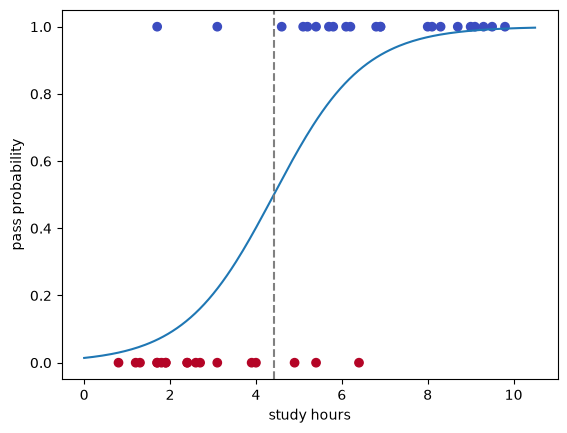

## 파트 2. 타이타닉: 누가 살아남았나

1912년 타이타닉 승객 891명. `survived` (1 = 생존) 를 성별 · 객실 등급 · 나이로 예측한다. 처음 실행하면 CSV 를 내려받는다.

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/titanic.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/titanic.csv")
df = pd.read_csv("data/titanic.csv")
df = df.dropna(subset=["age"])                             # drop passengers with unknown age (see the dirty data lesson!)
df["female"] = (df["sex"] == "female").astype(int)
df["first_class"] = (df["pclass"] == 1).astype(int)
df["third_class"] = (df["pclass"] == 3).astype(int)
feats = ["female", "first_class", "third_class", "age"]
print(len(df), "passengers, survival rate", f"{df.survived.mean():.0%}")
df[feats + ["survived"]].head()

**예상 결과**

```
714 passengers, survival rate 41%
   female  first_class  third_class   age  survived
0       0            0            1  22.0         0
1       1            1            0  38.0         1
2       1            0            1  26.0         1
3       1            1            0  35.0         1
4       0            0            1  35.0         0
```

In [ ]:
model = LogisticRegression(max_iter=1000).fit(df[feats], df["survived"])
for name, w in zip(feats, model.coef_[0]):
    odds = None             # TODO: odds ratio e^w
    print(f"{name:12s} w = {w:+.3f}   odds x{odds:.2f}")
print("\nReading: the female odds ratio = how many times higher a woman's survival odds are than a man's, at the same class and age")

**예상 결과**

```
female       w = +2.405   odds x11.08
first_class  w = +1.231   odds x3.43
third_class  w = -1.223   odds x0.29
age          w = -0.036   odds x0.97

Reading: the female odds ratio = how many times higher a woman's survival odds are than a man's, at the same class and age
```

In [ ]:
# Ask the model: 20-year-old woman in 1st class vs 20-year-old man in 3rd class
ask = pd.DataFrame([[1, 1, 0, 20], [0, 0, 1, 20]], columns=feats)
for desc, p in zip(["woman, 20, 1st class", "man, 20, 3rd class"], model.predict_proba(ask)[:, 1]):
    print(f"{desc}: survival probability {p:.0%}")

**예상 결과**

```
woman, 20, 1st class: survival probability 95%
man, 20, 3rd class: survival probability 12%
```

## 파트 3. 임계값과 PR 곡선

`predict` 는 확률 0.5 를 기준으로 자른다. 기준을 바꾸면 정밀도와 재현율이 어떻게 바뀔까?

In [ ]:
from sklearn.metrics import precision_score, recall_score, precision_recall_curve, average_precision_score
p = model.predict_proba(df[feats])[:, 1]
for th in [0.3, 0.5, 0.7]:
    pred = None             # TODO: 1 if probability >= th
    print(f"threshold {th}: precision {precision_score(df.survived, pred):.2f}  recall {recall_score(df.survived, pred):.2f}")

prec, rec, _ = precision_recall_curve(df.survived, p)
plt.plot(rec, prec); plt.xlabel("recall"); plt.ylabel("precision")
plt.title(f"PR curve  (PR-AUC = {average_precision_score(df.survived, p):.2f}; random guessing = survival rate {df.survived.mean():.2f})")
plt.show()

**예상 결과**

```
threshold 0.3: precision 0.66  recall 0.84
threshold 0.5: precision 0.76  recall 0.71
threshold 0.7: precision 0.92  recall 0.53
```

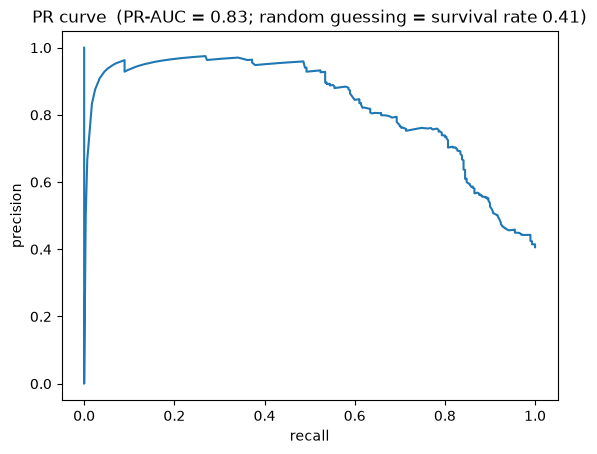

**확인 질문**
1. 파트 1 에서 선형회귀와 다른 줄은 정확히 어디인가? 기울기 식은 왜 같은 모양일까? (슬라이드의 약분)
2. 파트 2 에서 `third_class` 의 오즈 배수가 1 보다 작다는 것은 무슨 뜻인가?
3. 파트 2 에서 나이를 모르는 승객 177명을 뺐다. 이게 결과를 어떻게 바꿀 수 있을까?
4. 구명보트에 태울 사람을 고르는 상황이라면 임계값을 올릴까 내릴까? 이유는?

데이터 출처: Titanic passenger data (Encyclopedia Titanica 기반, seaborn-data 사본).